In [1]:
import numpy as np
from lib import *
from tqdm.notebook import tqdm

## Veify one layer closed and recurrent form

In [2]:
k = 4
T = 5

alpha = sorted(complex_random((k)), key=np.abs)

Y = np.diag(alpha)
W = complex_random((k,1))
V = complex_random((k,1))
x = complex_random((T))
np.allclose(one_layer_recurrent(Y, W, V, x), one_layer_closed_form(Y, W, V, x))

True

## Verify n_layer_recurrent corresponds to one_layer_recurrent when n=1

In [3]:
m = 8 # hidden dim
n = 1 # num of layers
T = 40

A = complex_random((n, m, m))
B =  [complex_random((m, 1))] + [complex_random((m, m)) for _ in range(n-1)]
C = complex_random((m, 1))
x = complex_random((T))

np.allclose(one_layer_recurrent(A[0], B[0], C, x), n_layer_recurrent(A, B, C, x))

True

## Verify n_layer_recurrent n_layer_closed_form are same

In [4]:
m =  4# hidden dim
n = 2 # num of layers
T = 6

# Generate sorted eignenvalues and reshape in to A
alpha = sorted(complex_random((n*m)), key=np.abs)
alpha = np.array(alpha).reshape((n, m))
A = []
for a in alpha:
    A.append(np.diag(a))
A = np.array(A)


B =  [complex_random((m, 1))] + [complex_random((m, m)) for _ in range(n-1)]
C = complex_random((m, 1))
x = complex_random((T))

In [5]:
np.allclose(n_layer_recurrent(A, B, C, x), n_layer_recurrent_closed_form(A, B, C, x))

True

In [6]:
m = 64 # hidden dim
n = 6 # num of layers
k = n*(m-1)+1 # dim for one layer 

print(k)
T = 32

alpha = sorted(complex_random((k)), key=np.abs)

Y = np.diag(alpha)
W = complex_random((k,1))
V = complex_random((k,1))
x = complex_random((T))

379


In [7]:
np.allclose(one_layer_closed_form(Y, W, V, x), n_layer_recurrent(*get_n_layer_param(alpha,W,V, n,m), x))

True

In [2]:
import numpy as np

def divide_circle(k, length=1.0):
    perturbe = np.random.random(k)+0.5
    # Evenly spaced angles between 0 and 2π
    theta = np.linspace(0, 2 * np.pi, k, endpoint=False)
    # Compute real and imaginary parts
    real = np.cos(theta) * length
    imag = np.sin(theta) * length
    # Combine into complex numbers
    complex_numbers = real + 1j * imag
    return np.array(complex_numbers)


In [11]:
import numpy as np
from lib import *
from tqdm.notebook import tqdm

k = 2521 # dim for one layer
max_norm =[]
layers = []
alpha = sorted(complex_random((k)), key=np.abs)
alpha = alpha / np.abs(alpha).max()
# alpha = np.array(sorted(divide_circle(k, length=0.9), key=np.abs))
Y = np.diag(alpha)
W = complex_random((k,1))*100
V = complex_random((k,1))*100


# alpha = sorted(np.random.random((k)), key=np.abs)+0.05
# alpha = alpha / np.abs(alpha).max()
# Y = np.diag(alpha)
# W = np.random.random((k,1))*1
# V = np.random.random((k,1))*1


a = np.abs(W*V).max()

for n in tqdm(range(2,64)):
    if (k-1) % n == 0:
        m = int((k-1) / n + 1)
        # print(f'n: {n}, m: {m}')
        # Generate sorted eignenvalues and reshape in to A
        layers.append(n)
        
        
        A,B,C = get_n_layer_param(alpha,W,V, n,m, real=False)

        b_max = 0

        for b in B:
            b_max = max(b_max, np.abs(b).max())

        max_norm.append(max(np.abs(C).max(), b_max).item())



  0%|          | 0/62 [00:00<?, ?it/s]

In [12]:
import matplotlib.pyplot as plt
layers = np.array(layers)

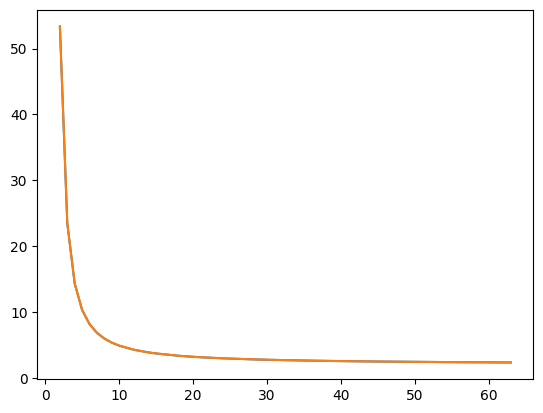

In [13]:
plt.plot(layers, max_norm)

# plt.plot(layers, 1*(((a)**(1/(layers+1)))))

# plt.plot(layers, 1*(((layers*a)**(1/(layers+1)))))

plt.plot(layers, 2*(a)**(1/(layers+1)))

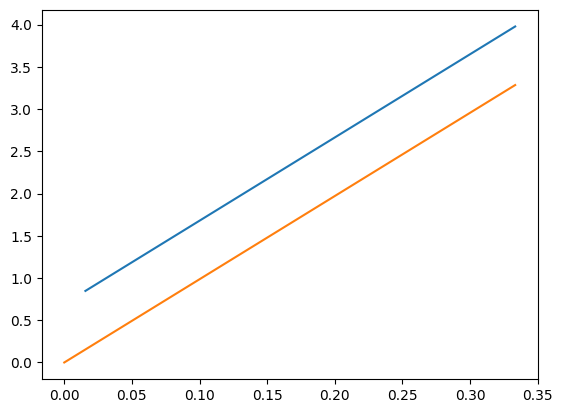

In [26]:
import seaborn as sns

plt.plot(1/(layers+1), np.log(max_norm))


x = np.linspace(0,max(1/(layers+1)),10)
plt.plot(x, np.log(a)*x)

